In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import (
    train_test_split, KFold, StratifiedKFold, RepeatedStratifiedKFold,
    TimeSeriesSplit, GroupKFold, cross_val_predict, cross_val_score
)
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve
)

from imblearn.over_sampling import SMOTE

# Load the uploaded Titanic dataset
raw_data = pd.read_csv("/content/titanic.csv")
# These are the actual column names in this file.
feature_columns = ["Pclass", "Gender", "Age", "SibSp", "Parch", "Fare"]
data = raw_data[["Survived"] + feature_columns].copy()

# Keep Ticket separately for Group K-Fold.
# Ticket is a grouping variable, not a model feature.
group_labels = raw_data.loc[data.index, "Ticket"].fillna(
    pd.Series(data.index.astype(str), index=data.index)
).astype(str)

# Encode the actual Gender column.
encoder = LabelEncoder()
data["Gender"] = encoder.fit_transform(data["Gender"].astype(str))

# Fill missing Age values so all 891 rows can be used.
age_imputer = SimpleImputer(strategy="median")
data[["Age"]] = age_imputer.fit_transform(data[["Age"]])

# Separate input features (X) and target (y).
X = data.drop("Survived", axis=1)
y = data["Survived"]
print("Dataset shape:", data.shape)
print("Original CSV shape:", raw_data.shape)
print("Feature columns:", list(X.columns))
display(data.head())

print("\nSurvival counts:")
print(y.value_counts())

print("\nMissing values after preprocessing:")
print(data.isna().sum())

print("\nNumber of ticket groups:", group_labels.nunique())



Dataset shape: (891, 7)
Original CSV shape: (891, 12)
Feature columns: ['Pclass', 'Gender', 'Age', 'SibSp', 'Parch', 'Fare']


,Survived,Pclass,Gender,Age,SibSp,Parch,Fare
0,0,3,1,22.0,1,0,7.2500
1,1,1,0,38.0,1,0,71.2833
2,1,3,0,26.0,0,0,7.9250
3,1,1,0,35.0,1,0,53.1000
4,0,3,1,35.0,0,0,8.0500



Survival counts:
Survived
0    549
1    342
Name: count, dtype: int64

Missing values after preprocessing:
Survived    0
Pclass      0
Gender      0
Age         0
SibSp       0
Parch       0
Fare        0
dtype: int64

Number of ticket groups: 683


In [2]:
# First, separate 20% test data
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Split the remaining 80% into training (60%) and validation (20%)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp
)

depth_values = [2, 4, 6, 8, None]
results = []

# Train one Random Forest for each depth
for depth in depth_values:
    model = RandomForestClassifier(max_depth=depth, random_state=42)
    model.fit(X_train, y_train)

    train_accuracy = accuracy_score(y_train, model.predict(X_train))
    val_accuracy = accuracy_score(y_val, model.predict(X_val))

    results.append([depth, train_accuracy, val_accuracy])
# Show the results in a table
split_results = pd.DataFrame(
    results, columns=["Max Depth", "Training Accuracy", "Validation Accuracy"]
)
display(split_results)

# Select the depth with the highest validation accuracy
best_depth = split_results.loc[
    split_results["Validation Accuracy"].idxmax(), "Max Depth"
]
if pd.isna(best_depth):
    best_depth = None
print("Best depth:", best_depth)

# Train the selected model and evaluate it on the test data
best_model = RandomForestClassifier(max_depth=best_depth, random_state=42)
best_model.fit(X_train, y_train)

print("Final training accuracy:", accuracy_score(y_train, best_model.predict(X_train)))
print("Final validation accuracy:", accuracy_score(y_val, best_model.predict(X_val)))
print("Final test accuracy:", accuracy_score(y_test, best_model.predict(X_test)))


,Max Depth,Training Accuracy,Validation Accuracy
0,2.0,0.792135,0.792135
1,4.0,0.844569,0.837079
2,6.0,0.891386,0.825843
3,8.0,0.923221,0.837079
4,NaN,0.986891,0.853933


Best depth: None
Final training accuracy: 0.9868913857677902
Final validation accuracy: 0.8539325842696629
Final test accuracy: 0.7932960893854749


In [3]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
model = RandomForestClassifier(random_state=42)

# Get predictions for rows when they are in a test fold
predictions = cross_val_predict(model, X, y, cv=folds)

# Get predicted probabilities for the ROC curve and AUC
probabilities = cross_val_predict(
    model, X, y, cv=folds, method="predict_proba"
)[:, 1]

# Confusion matrix values
tn, fp, fn, tp = confusion_matrix(y, predictions).ravel()

accuracy = accuracy_score(y, predictions)
precision = precision_score(y, predictions, zero_division=0)
recall = recall_score(y, predictions, zero_division=0)
f1 = f1_score(y, predictions, zero_division=0)
specificity = tn / (tn + fp)
auc = roc_auc_score(y, probabilities)

print("Confusion Matrix:")
print(confusion_matrix(y, predictions))
print("\nEvaluation Results")
print("Accuracy:", round(accuracy, 3))
print("Precision:", round(precision, 3))
print("Recall:", round(recall, 3))
print("F1-score:", round(f1, 3))
print("Specificity:", round(specificity, 3))
print("ROC-AUC:", round(auc, 3))


Confusion Matrix:
[[476  73]
 [ 83 259]]

Evaluation Results
Accuracy: 0.825
Precision: 0.78
Recall: 0.757
F1-score: 0.769
Specificity: 0.867
ROC-AUC: 0.871


,Method,Mean Accuracy,Std Accuracy,Number of Test Splits
0,Hold-Out,0.810,0.000,1
1,K-Fold,0.815,0.015,5
2,Stratified K-Fold,0.825,0.022,5
3,Repeated K-Fold,0.819,0.018,15
4,Time Series Split (row order demo),0.792,0.045,5
5,Group K-Fold (Ticket groups),0.804,0.017,5


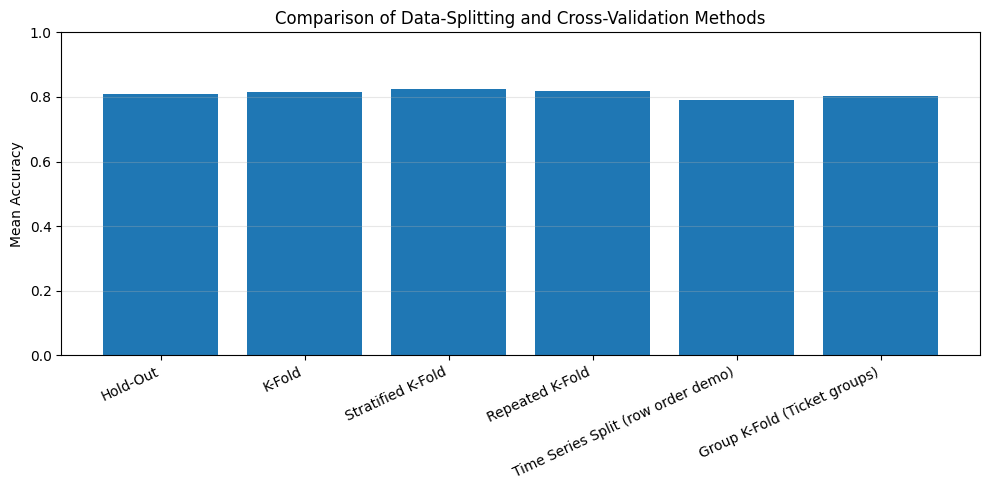

In [7]:
comparison_model = RandomForestClassifier(
    n_estimators=100, random_state=42
)

comparison_results = []

# 1. Hold-Out: one 80/20 split
X_train_ho, X_test_ho, y_train_ho, y_test_ho = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
holdout_model = RandomForestClassifier(n_estimators=100, random_state=42)
holdout_model.fit(X_train_ho, y_train_ho)
holdout_accuracy = accuracy_score(y_test_ho, holdout_model.predict(X_test_ho))
comparison_results.append({
    "Method": "Hold-Out",
    "Mean Accuracy": holdout_accuracy,
    "Std Accuracy": 0.0,
    "Number of Test Splits": 1
})

# 2. K-Fold: five folds, without class stratification
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
kfold_scores = cross_val_score(
    comparison_model, X, y, cv=kfold, scoring="accuracy"
)
comparison_results.append({
    "Method": "K-Fold",
    "Mean Accuracy": kfold_scores.mean(),
    "Std Accuracy": kfold_scores.std(),
    "Number of Test Splits": len(kfold_scores)
})
# 3. Stratified K-Fold: five folds with similar class ratios
stratified_folds = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)
stratified_scores = cross_val_score(
    comparison_model, X, y, cv=stratified_folds, scoring="accuracy"
)
comparison_results.append({
    "Method": "Stratified K-Fold",
    "Mean Accuracy": stratified_scores.mean(),
    "Std Accuracy": stratified_scores.std(),
    "Number of Test Splits": len(stratified_scores)
})
# 4. Repeated K-Fold for classification: repeat stratified K-Fold 3 times
repeated_folds = RepeatedStratifiedKFold(
    n_splits=5, n_repeats=3, random_state=42
)
repeated_scores = cross_val_score(
    comparison_model, X, y, cv=repeated_folds, scoring="accuracy"
)
comparison_results.append({
    "Method": "Repeated K-Fold",
    "Mean Accuracy": repeated_scores.mean(),
    "Std Accuracy": repeated_scores.std(),
    "Number of Test Splits": len(repeated_scores)
})
# 5. Time Series Split: earlier rows train, later rows test.
# Titanic has no timestamp, so this is only a row-order demonstration.
time_folds = TimeSeriesSplit(n_splits=5)
time_scores = cross_val_score(
    comparison_model, X.reset_index(drop=True), y.reset_index(drop=True),
    cv=time_folds, scoring="accuracy"
)
comparison_results.append({
    "Method": "Time Series Split (row order demo)",
    "Mean Accuracy": time_scores.mean(),
    "Std Accuracy": time_scores.std(),
    "Number of Test Splits": len(time_scores)
})
# 6. Group K-Fold: all rows with the same ticket stay in one group
if group_labels.nunique() >= 5:
    group_folds = GroupKFold(n_splits=5)
    group_scores = cross_val_score(
        comparison_model, X, y, cv=group_folds,
        groups=group_labels, scoring="accuracy"
    )
    comparison_results.append({
        "Method": "Group K-Fold (Ticket groups)",
        "Mean Accuracy": group_scores.mean(),
        "Std Accuracy": group_scores.std(),
        "Number of Test Splits": len(group_scores)
    })
else:
    print("Group K-Fold skipped: fewer than 5 unique groups are available.")

cv_comparison_table = pd.DataFrame(comparison_results)
display(cv_comparison_table.round(3))
# Visual comparison of mean accuracy
plt.figure(figsize=(10, 5))
plt.bar(
    cv_comparison_table["Method"],
    cv_comparison_table["Mean Accuracy"]
)
plt.ylabel("Mean Accuracy")
plt.title("Comparison of Data-Splitting and Cross-Validation Methods")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

